Tutorial 03
World Projection and Coordinates System

1. import the libraries

In [2]:
# import the libraries

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pyproj
from matplotlib.backends.backend_pdf import PdfPages
from shapely.geometry import LineString, MultiLineString, Point

In [7]:
# Add the world cities and world countries

cities = gpd.read_file("/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/tutorial03-data/World_Cities/World_Cities.shp")
countries = gpd.read_file("/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/tutorial03-data/World_Countries_files/World_Countries.shp")
grid = gpd.read_file("/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/tutorial03-data/latlong/latlong.shp")

In [9]:
#look the attribute of the grid

grid.head()

,OBJECTID,VALUE,DEGREE5,DEGREE10,DEGREE15,DEGREE20,DEGREE30,Shape_Leng,geometry
0,1079.0,90S,Y,Y,Y,N,Y,1.0,"LINESTRING (180 -90, 179 -90)"
1,130140.0,180E,Y,Y,Y,Y,Y,1.0,"LINESTRING (180 -89, 180 -90)"
2,1077.0,179E,N,N,N,N,N,1.0,"LINESTRING (179 -89, 179 -90)"
3,358.0,90S,Y,Y,Y,N,Y,1.0,"LINESTRING (179 -90, 178 -90)"
4,357.0,90S,Y,Y,Y,N,Y,1.0,"LINESTRING (178 -90, 177 -90)"


In [11]:
#print axis each 5 degree

grid_5deg = grid[grid["DEGREE5"] == "Y"]
print(len(grid), len(grid_5deg))

130140 26460


In [12]:
# inspect projections

print(cities.crs)
print(countries.crs)
print(grid.crs)

EPSG:3857
EPSG:3857
EPSG:4326


In [13]:
#mismatch between the EPSG - all three need to be WGS 84
#to see the same data seen in QGIS

countries.crs.to_wkt(pretty=True)

'PROJCRS["WGS 84 / Pseudo-Mercator",\n    BASEGEOGCRS["WGS 84",\n        ENSEMBLE["World Geodetic System 1984 ensemble",\n            MEMBER["World Geodetic System 1984 (Transit)"],\n            MEMBER["World Geodetic System 1984 (G730)"],\n            MEMBER["World Geodetic System 1984 (G873)"],\n            MEMBER["World Geodetic System 1984 (G1150)"],\n            MEMBER["World Geodetic System 1984 (G1674)"],\n            MEMBER["World Geodetic System 1984 (G1762)"],\n            MEMBER["World Geodetic System 1984 (G2139)"],\n            MEMBER["World Geodetic System 1984 (G2296)"],\n            ELLIPSOID["WGS 84",6378137,298.257223563,\n                LENGTHUNIT["metre",1]],\n            ENSEMBLEACCURACY[2.0]],\n        PRIMEM["Greenwich",0,\n            ANGLEUNIT["degree",0.0174532925199433]],\n        ID["EPSG",4326]],\n    CONVERSION["Popular Visualisation Pseudo-Mercator",\n        METHOD["Popular Visualisation Pseudo Mercator",\n            ID["EPSG",1024]],\n        PARAMETE

In [15]:
#converting the projection

cities = cities.to_crs(epsg=4326)
countries = countries.to_crs(epsg=4326)

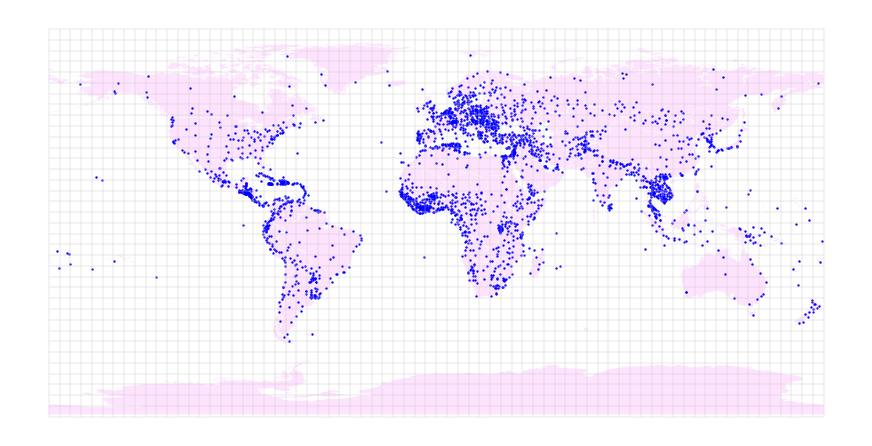

In [20]:
#set the dimension of the image
fig, ax =plt.subplots(figsize=(11, 8.5))

countries.plot(ax=ax, facecolor="#fee3ff", edgecolor="#ffffff", linewidth=0.2)
cities.plot(ax=ax, color="#0000ff", markersize=0.5)
grid_5deg.plot(ax=ax, color="#c9c9c9", linewidth=0.3)

ax.set_axis_off()

In [23]:
#change the map document's projection
#ESRI --> communicate in which registry to look in

target_crs = pyproj.CRS("ESRI:54027")

print(target_crs.name)
print(target_crs.axis_info[0].unit_name)

World_Equidistant_Conic
metre


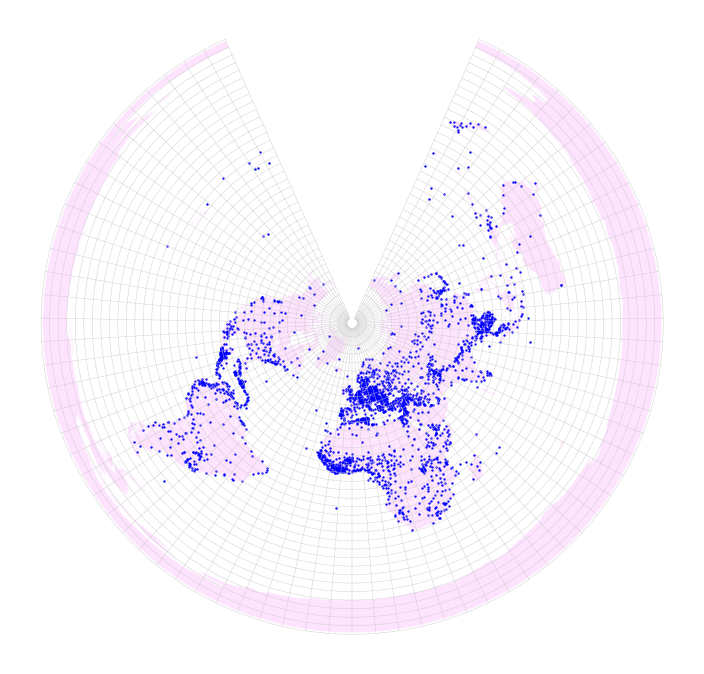

In [ ]:
fig, ax =plt.subplots(figsize=(11, 8.5))

countries.to_crs("ESRI:54027").plot(ax=ax, facecolor="#fee3ff", edgecolor="#ffffff", linewidth=0.2)
cities.to_crs("ESRI:54027").plot(ax=ax, color="#0000ff", markersize=0.5)
grid_5deg.to_crs("ESRI:54027").plot(ax=ax, color="#c9c9c9", linewidth=0.3)

ax.set_axis_off()

In [27]:
# to_crs() reprojects: 
# it recalculates every coordinate into the new coordinate reference system

# set_crs() only changes the label: 
# it declares which coordinate reference system the existing coordinates are in, without touching them

In [28]:
countries_54027 = countries.to_crs("ESRI:54027")
cities_54027 = cities.to_crs("ESRI:54027")

print(countries_54027.crs.name)

World_Equidistant_Conic


In [ ]:
#export

countries_54027.to_file("/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/Tutorial03_output/countries_54027.shp")
cities_54027.to_file("/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/Tutorial03_output/cities_54027.shp")

In [30]:
print(countries_54027.total_bounds)

[-20236029.37602246  -9890271.86438868  20236029.42241617
  28815695.9605588 ]


In [32]:
# add the new layer

paths = gpd.read_file("/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/Tutorial03_output/city-paths.dxf")
print(paths.crs)
paths.head()

None


,Layer,PaperSpace,SubClasses,Linetype,EntityHandle,Text,geometry
0,Lines,NaN,AcDbEntity:AcDbLine,None,60,None,"LINESTRING Z (734984.273 5088641.739 0, 867202..."
1,Lines,NaN,AcDbEntity:AcDbLine,None,61,None,"LINESTRING Z (734984.273 5088641.739 0, 265548..."
2,Lines,NaN,AcDbEntity:AcDbLine,None,62,None,"LINESTRING Z (734984.273 5088641.739 0, -70605..."
3,Lines,NaN,AcDbEntity:AcDbLine,None,63,None,"LINESTRING Z (734984.273 5088641.739 0, 269221..."
4,Lines,NaN,AcDbEntity:AcDbLine,None,64,None,"LINESTRING Z (734984.273 5088641.739 0, -89214..."


In [33]:
# there are no coordinates
# but the map and the line use the same unit
# create a crs

paths = paths.set_crs("ESRI:54027")
paths = paths.set_geometry(paths.geometry.force_2d())
paths = paths[paths.geom_type == "LineString"].reset_index(drop=True)
print(paths.crs, len(paths))

ESRI:54027 10


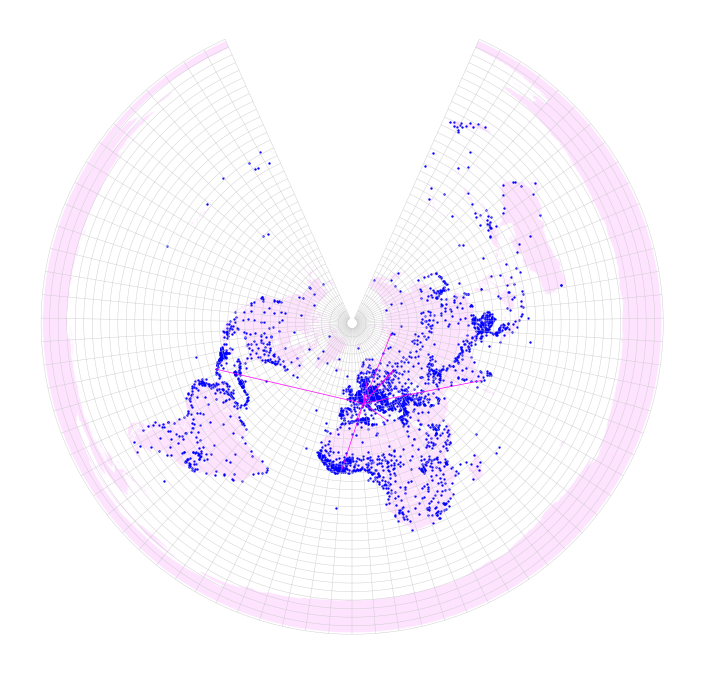

In [ ]:
fig, ax = plt.subplots(figsize=(11, 8.5))ax=ax, facecolor="#fee3ff", edgecolor="#ffffff", linewidth=0.2
countries_54027.plot()
grid_5deg.to_crs("ESRI:54027").plot(ax=ax, color="#c9c9c9", linewidth=0.3)
cities_54027.plot(ax=ax, color="#0000ff", markersize=0.5)
paths.plot(ax=ax, color="#ff00ff", linewidth=0.5)
ax.set_axis_off()

In [35]:
paths.to_file("/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/Tutorial03_output/city_paths_54027.shp")

/var/folders/0m/bvcl4xxj2c17g98yg850gq0h0000gn/T/ipykernel_54696/1627040224.py:1: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  paths.to_file("/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/Tutorial03_output/city_paths_54027.shp")
/opt/miniconda3/envs/cdp/lib/python3.14/site-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'EntityHandle' to 'EntityHand'
  ogr_write(


In [36]:
def nearest_city(point):
    return cities_54027.distance(point).idxmin()

# get the first coordinate point of the line and find the nearest city
from_index = [nearest_city(Point(line.coords[0])) for line in paths.geometry]

# get the last coordinate point of the line and find the nearest city
to_index = [nearest_city(Point(line.coords[-1])) for line in paths.geometry]

# create new atributes on the lines indicating to and from cities
paths["from_city"] = cities_54027.loc[from_index, "CITY_NAME"].values
paths["to_city"] = cities_54027.loc[to_index, "CITY_NAME"].values

# subset the cities to only include those connected by your lines,
# using a sorted set to avoid duplicates
my_cities = cities_54027.loc[sorted(set(from_index + to_index))]
paths[["from_city", "to_city"]]

,from_city,to_city
0,Milan,Leipzig
1,Milan,Medea
2,Milan,Tiassale
3,Milan,Yaskar-Ola
4,Milan,David
5,Milan,Dudinka
6,Milan,Stockholm
7,Milan,Ceboksary
8,Milan,Cochin
9,Milan,Darnah


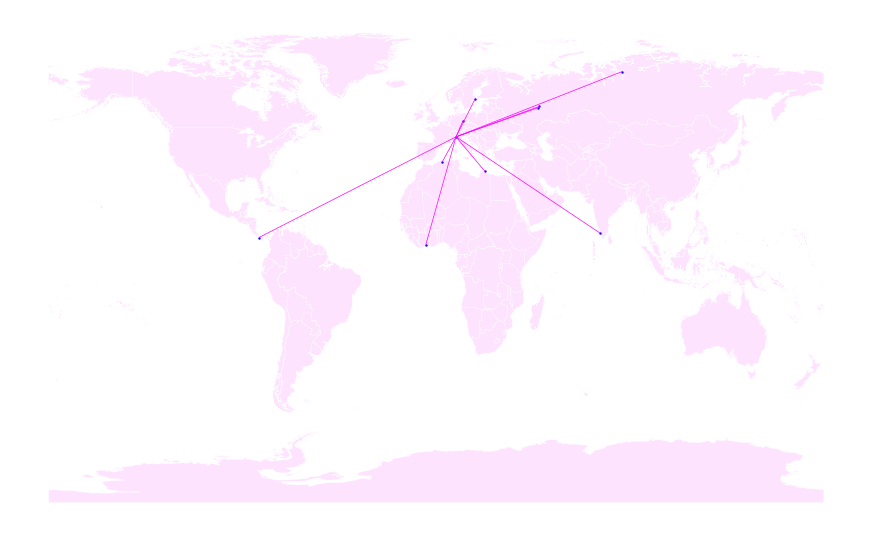

In [ ]:
#inspecting results

fig, ax = plt.subplots(figsize=(11, 8.5))

countries.plot(ax=ax, facecolor="#fee3ff", edgecolor="#ffffff", linewidth=0.2)
paths.to_crs(4326).plot(ax=ax, color="#ff00ff", linewidth=0.5)
my_cities.to_crs(4326).plot(ax=ax, color="#0000ff", markersize=0.5)

ax.set_axis_off()

In [39]:
# add segments each 50km

drawn_lines_conic = paths.segmentize(50_000)

In [40]:
to_lonlat = pyproj.Transformer.from_crs("ESRI:54027", 4326, always_xy=True)
to_conic = pyproj.Transformer.from_crs(4326, "ESRI:54027", always_xy=True)

In [41]:
def break_line(coords, keep=None):
    '''
    Breaks a line into pieces wherever it cannot be drawn continuously on a flat map.

    coords: coordinates to assess
    keep: boolean array indicating which coordinates to keep (based on whether or not they are in the representable area of the projected map)
    '''
    if keep is None:

        # create an array of True values for each coordinate
        keep = np.ones(len(coords), dtype=bool)

    pieces, piece = [], []
    for i, (lon, lat) in enumerate(coords):
    
        # assess whether the line crosses the antimeridian
        # the antimeridian is the line of longitude at 180 degrees east or west
        crosses_antimeridian = i > 0 and abs(lon - coords[i - 1, 0]) > 180
        if not keep[i] or crosses_antimeridian:

            if len(piece) > 1:
                pieces.append(piece)
            piece = []

        if keep[i]:
            piece.append((lon, lat))

    if len(piece) > 1:
        pieces.append(piece)

    return LineString(pieces[0]) if len(pieces) == 1 else MultiLineString(pieces)


def keep_on_earth(line_in_conic):
    # determine which coordinates are still on the earth after a round-trip projection
    x, y = np.array(line_in_conic.coords).T

    # project the coordinates from the conic projection back to longitude and latitude
    lon, lat = to_lonlat.transform(x, y)

    # project the coordinates back to the conic projection to see how far they moved
    x_back, y_back = to_conic.transform(lon, lat)

    # check which coordinates are still close to their original positions in the conic projection
    on_earth = np.hypot(x_back - x, y_back - y) < 1
    
    # break the line into pieces wherever it cannot be drawn continuously on a flat map. the on_earth array indicates which coordinates are still valid, and if not
    # they are dropped from the resulting line pieces.
    return break_line(np.column_stack([lon, lat]), on_earth)

In [42]:
drawn_lines = paths.copy()
drawn_lines["geometry"] = drawn_lines_conic.apply(keep_on_earth).set_crs(4326, allow_override=True)
drawn_lines["leaves_the_map"] = drawn_lines.geometry.count_coordinates() < drawn_lines_conic.count_coordinates()
drawn_lines[["from_city", "to_city", "leaves_the_map"]]

,from_city,to_city,leaves_the_map
0,Milan,Leipzig,False
1,Milan,Medea,False
2,Milan,Tiassale,False
3,Milan,Yaskar-Ola,False
4,Milan,David,False
5,Milan,Dudinka,False
6,Milan,Stockholm,False
7,Milan,Ceboksary,False
8,Milan,Cochin,False
9,Milan,Darnah,False


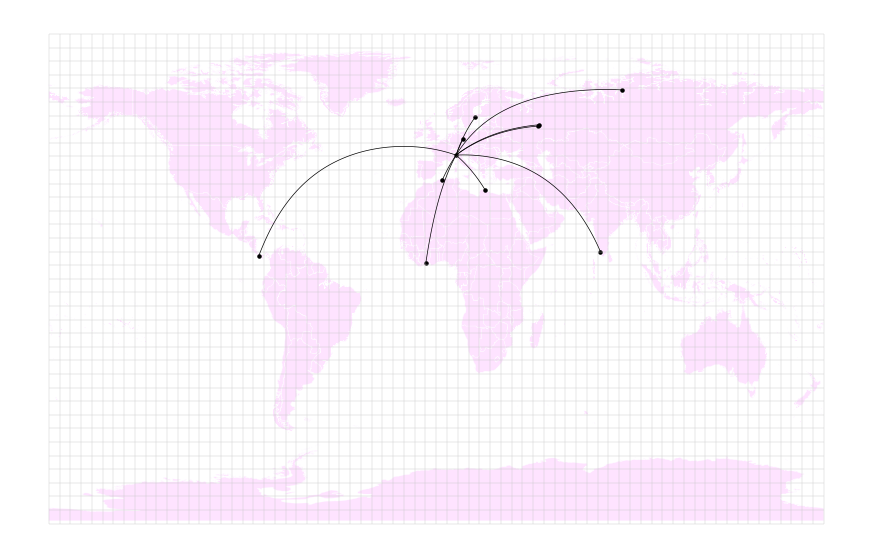

In [45]:
fig, ax = plt.subplots(figsize=(11, 8.5))

countries.plot(ax=ax, facecolor="#fee3ff", edgecolor="#ffffff", linewidth=0.2)
grid_5deg.plot(ax=ax, color="#c9c9c9", linewidth=0.3)
drawn_lines.plot(ax=ax, color="#000000", linewidth=0.5)
my_cities.to_crs(4326).plot(ax=ax, color="#000000", markersize=5)

ax.set_axis_off()

In [46]:
# measure the lines

geod = pyproj.Geod(ellps="WGS84")

In [47]:
# 1. The lenght rhino report
# 2. The length of the line you drew, measured along the surface of the earth
# 3. The shortest possible distance between the two cities

paths_4326 = paths.to_crs(4326)

distances = paths[["from_city", "to_city"]].copy()
distances["rhino_length_km"] = paths.length / 1000 # from meters

# filter out cases that pass outside the projected map surface
distances["drawn_line_on_earth_km"] = np.where(
    drawn_lines["leaves_the_map"], np.nan, drawn_lines.geometry.apply(geod.geometry_length) / 1000
)

# calculate the shortest path via the ellipsoid using pyproj
# pass in each line's endpoints to geod.inv to get the shortest distance across the ellipsoid, returning distance which is in the 2nd index of the tuple (meters)
distances["shortest_path_km"] = [
    geod.inv(*line.coords[0], *line.coords[-1])[2] / 1000 for line in paths_4326.geometry
]
distances.round()

,from_city,to_city,rhino_length_km,drawn_line_on_earth_km,shortest_path_km
0,Milan,Leipzig,696.0,695.0,695.0
1,Milan,Medea,1167.0,1156.0,1156.0
2,Milan,Tiassale,4642.0,4597.0,4593.0
3,Milan,Yaskar-Ola,2951.0,2932.0,2932.0
4,Milan,David,9916.0,9588.0,9474.0
5,Milan,Dudinka,4905.0,4875.0,4874.0
6,Milan,Stockholm,1653.0,1651.0,1651.0
7,Milan,Ceboksary,2907.0,2887.0,2887.0
8,Milan,Cochin,7859.0,7514.0,7442.0
9,Milan,Darnah,1861.0,1825.0,1824.0


In [48]:
# drawing the shortest path

def shortest_path(line, n_points=200):
    x0, y0 = line.coords[0][:2] # starting point
    x1, y1 = line.coords[-1][:2] # ending point
    
    # expand the array of coordinates to include the intermediate points along the geodesic: starting point, 200 intermediate points calculated, and ending point
    coords = np.array([(x0, y0), *geod.npts(x0, y0, x1, y1, n_points), (x1, y1)])
    return break_line(coords)


shortest_paths = paths_4326.copy()
shortest_paths["geometry"] = paths_4326.geometry.apply(shortest_path)

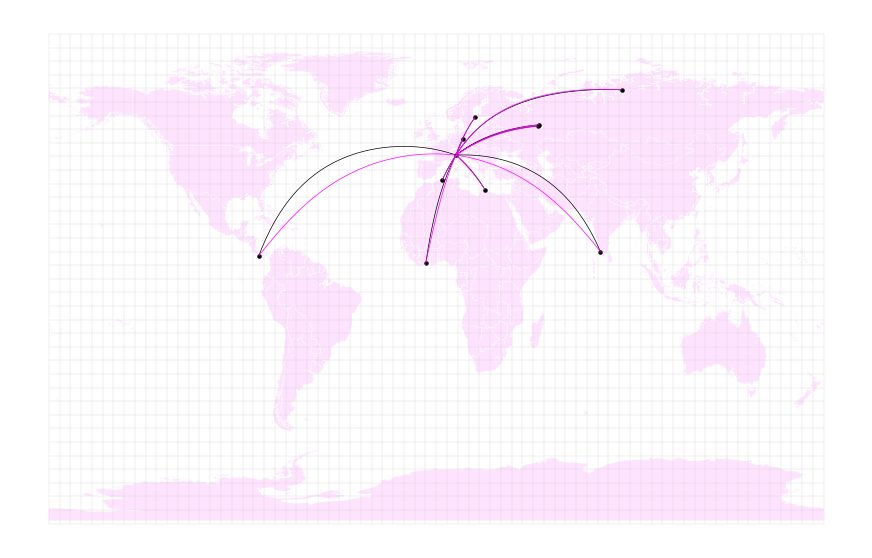

In [50]:
fig, ax = plt.subplots(figsize=(11, 8.5))

countries.plot(ax=ax, facecolor="#fee3ff", edgecolor="#ffffff", linewidth=0.2)
grid_5deg.plot(ax=ax, color="#c9c9c9", linewidth=0.2)
drawn_lines.plot(ax=ax, color="black", linewidth=0.5)
shortest_paths.plot(ax=ax, color="#ff00ff", linewidth=0.5)
my_cities.to_crs(4326).plot(ax=ax, color="black", markersize=5)


ax.set_axis_off()

In [51]:
# composing the map

world_projections = [
    (info.code, info.name)
    for info in pyproj.database.query_crs_info(auth_name="ESRI", pj_types="PROJECTED_CRS")
    if info.name.startswith("World_")
]
world_projections

[('54001', 'World_Plate_Carree'),
 ('54002', 'World_Equidistant_Cylindrical'),
 ('54003', 'World_Miller_Cylindrical'),
 ('54004', 'World_Mercator'),
 ('54008', 'World_Sinusoidal'),
 ('54009', 'World_Mollweide'),
 ('54010', 'World_Eckert_VI'),
 ('54011', 'World_Eckert_V'),
 ('54012', 'World_Eckert_IV'),
 ('54013', 'World_Eckert_III'),
 ('54014', 'World_Eckert_II'),
 ('54015', 'World_Eckert_I'),
 ('54016', 'World_Gall_Stereographic'),
 ('54017', 'World_Behrmann'),
 ('54018', 'World_Winkel_I'),
 ('54019', 'World_Winkel_II'),
 ('54021', 'World_Polyconic'),
 ('54022', 'World_Quartic_Authalic'),
 ('54023', 'World_Loximuthal'),
 ('54024', 'World_Bonne'),
 ('54025', 'World_Hotine'),
 ('54026', 'World_Stereographic'),
 ('54027', 'World_Equidistant_Conic'),
 ('54028', 'World_Cassini'),
 ('54029', 'World_Van_der_Grinten_I'),
 ('54030', 'World_Robinson'),
 ('54031', 'World_Two_Point_Equidistant'),
 ('54032', 'World_Azimuthal_Equidistant'),
 ('54034', 'World_Cylindrical_Equal_Area'),
 ('54042', 'Wo

In [58]:
# install adjustText per cambiare il font

%pip install adjustText

Note: you may need to restart the kernel to use updated packages.


In [62]:
from adjustText import adjust_text

plt.rcParams["font.family"] = "Courier"
plt.rcParams["font.weight"] = "normal"

In [63]:
from adjustText import adjust_text

plt.rcParams["font.family"] = ["Courier", "DejaVu Sans Mono"]  # Courier, con un font alternativo se non disponibile
plt.rcParams["font.weight"] = "normal"

projections = {
    "Equidistant Conic": "ESRI:54027",
    "Robinson": "ESRI:54030",
    "Gall Stereographic": "ESRI:54016",
    "Mollweide": "ESRI:54009",
}

with PdfPages("tutorial03_maps.pdf") as pdf:
    for name, crs in projections.items():

        # page size in inches: 11 x 8.5 is a landscape letter page
        fig, ax = plt.subplots(figsize=(11, 8.5))

        # prep and map the data layers in each projection
        countries.to_crs(crs).plot(ax=ax, facecolor="#fee3ff", edgecolor="#ffffff", linewidth=0.2, rasterized=True)
        grid_5deg.to_crs(crs).plot(ax=ax, color="#c9c9c9", linewidth=0.2)
        drawn_lines.to_crs(crs).plot(ax=ax, color="#000000", linewidth=0.8, label="Line drawn in Rhino (straight in the Equidistant Conic projection)")
        shortest_paths.to_crs(crs).plot(ax=ax, color="#ff00ff", linewidth=0.5, label="Shortest path on the earth")
        cities_in_crs = my_cities.to_crs(crs)
        cities_in_crs.plot(ax=ax, color="#000000", markersize=5)

        texts = []  # Collect all labels for this page

        # label each city
        for city in cities_in_crs.itertuples():
            texts.append(ax.text(city.geometry.x, city.geometry.y, city.CITY_NAME, fontsize=4, ha="left", va="bottom"))

        # label each shortest path with its distance at its midpoint
        for line, km in zip(shortest_paths.to_crs(crs).geometry, distances["shortest_path_km"]):
            midpoint = line.interpolate(0.5, normalized=True)
            texts.append(ax.text(midpoint.x, midpoint.y, f"{km:,.0f} km", fontsize=4, color="#ff00ff", ha="center"))

        # prep the title, legend, and other map elements
        ax.set_title(f"{name} projection ({crs})", loc="left", fontsize=7)
        ax.legend(loc="lower left", frameon=False, prop={"family": ["Courier", "DejaVu Sans Mono"], "weight": "normal", "size": 7})
        ax.set_axis_off()
        fig.text(0.05, 0.03, "Data: World Cities and World Countries, Esri; World Latitude and Longitude Grids. Map by: Michelle Nuccio", fontsize=5)

        # Move labels to reduce overlaps
        adjust_text(texts, x=cities_in_crs.geometry.x.to_numpy(), y=cities_in_crs.geometry.y.to_numpy(), ax=ax, expand=(1.2, 1.4), arrowprops=dict(arrowstyle="-", color="#777777", lw=0.3), iter_lim=500)

        pdf.savefig(fig)
        plt.close(fig)